In [1]:
import requests
import pandas as pd
import os
import matplotlib.pyplot as plt

In [2]:
URL = "https://api.energidataservice.dk/dataset/PrivateConsumptionHeatingHour"

params = {
    "start": "2025-01-01",
    "end": "2025-12-31",
    "filter": '{"MunicipalityCode":["461"]}',
    "sort": "TimeDK asc",
    "limit": 0
}

In [3]:
parquet_file_path = r"C:\Users\simon\Desktop\Data Engineering Journey\Weather-Energy_project\odense_heating_consumption_2025.parquet"

if os.path.exists(parquet_file_path):
    
    print("Parquet file found. Loading local data")
    df = pd.read_parquet(parquet_file_path)

else:    
    
    response = requests.get(URL, params=params, timeout=5) # The response Object contains the server's response to the HTTP request.
    
    # Raise an HTTPError object, if an error occur.
    response.raise_for_status() 
    
    if response.status_code == 200:
        
        # Retrieve the data from the response 
        data = response.json()
        print("Download completed!")
        
        # Transform the JSON dataset to a dataframe
        df = pd.DataFrame(data["records"])

        # Save the data in parquet format: 
        df.to_parquet("odense_heating_consumption_2025.parquet", index=False)


Download completed!


A **Parquet** is a columnar storage file format for which data are stored column by column instead of row by row (like CSV and JSON).
It is efficient for data storage and analytical queries

In [4]:
print(f"Total records:{len(df)}\n")
print(df.info())

Total records:17472

<class 'pandas.DataFrame'>
RangeIndex: 17472 entries, 0 to 17471
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   TimeUTC           17472 non-null  str    
 1   TimeDK            17472 non-null  str    
 2   MunicipalityCode  17472 non-null  int64  
 3   Municipality      17472 non-null  str    
 4   RegionName        17472 non-null  str    
 5   HousingCategory   17472 non-null  str    
 6   HeatingCategory   17472 non-null  str    
 7   ConsumptionkWh    17472 non-null  float64
dtypes: float64(1), int64(1), str(6)
memory usage: 2.4 MB
None


In [5]:
df.head()

,TimeUTC,TimeDK,MunicipalityCode,Municipality,RegionName,HousingCategory,HeatingCategory,ConsumptionkWh
0,2024-12-31T23:00:00,2025-01-01T00:00:00,461,Odense,Region Syddanmark,Ukendt,Elvarme eller varmepumpe,1363.804
1,2024-12-31T23:00:00,2025-01-01T00:00:00,461,Odense,Region Syddanmark,Ukendt,Andet,26823.290
2,2025-01-01T00:00:00,2025-01-01T01:00:00,461,Odense,Region Syddanmark,Ukendt,Elvarme eller varmepumpe,1423.558
3,2025-01-01T00:00:00,2025-01-01T01:00:00,461,Odense,Region Syddanmark,Ukendt,Andet,27063.701
4,2025-01-01T01:00:00,2025-01-01T02:00:00,461,Odense,Region Syddanmark,Ukendt,Andet,26182.030


In [6]:
df.tail()

,TimeUTC,TimeDK,MunicipalityCode,Municipality,RegionName,HousingCategory,HeatingCategory,ConsumptionkWh
17467,2025-12-30T20:00:00,2025-12-30T21:00:00,461,Odense,Region Syddanmark,Ukendt,Andet,35816.025
17468,2025-12-30T21:00:00,2025-12-30T22:00:00,461,Odense,Region Syddanmark,Ukendt,Andet,33574.208
17469,2025-12-30T21:00:00,2025-12-30T22:00:00,461,Odense,Region Syddanmark,Ukendt,Elvarme eller varmepumpe,2084.277
17470,2025-12-30T22:00:00,2025-12-30T23:00:00,461,Odense,Region Syddanmark,Ukendt,Elvarme eller varmepumpe,2076.288
17471,2025-12-30T22:00:00,2025-12-30T23:00:00,461,Odense,Region Syddanmark,Ukendt,Andet,31004.370


In [7]:
print(df.columns.tolist())

['TimeUTC', 'TimeDK', 'MunicipalityCode', 'Municipality', 'RegionName', 'HousingCategory', 'HeatingCategory', 'ConsumptionkWh']


In [8]:
print("The different housing categories:\n",df["HousingCategory"].unique())
print("\nThe different heating categories:\n",df["HeatingCategory"].unique())

The different housing categories:
 <ArrowStringArray>
['Ukendt']
Length: 1, dtype: str

The different heating categories:
 <ArrowStringArray>
['Elvarme eller varmepumpe', 'Andet']
Length: 2, dtype: str


In [9]:
print("number of records:",len(df["TimeDK"]))
print("Count of the total number of days in the dataset",(len(df["TimeDK"])//2)//24)

number of records: 17472
Count of the total number of days in the dataset 364


In [10]:
if 'timeUTC' in df.columns:
    df = df.drop('TimeUTC', axis=1)
else:
    print("timeUTC column already dropped")

# Convert the Municipality code into a string
df['MunicipalityCode'] = df['MunicipalityCode'].astype(str)


timeUTC column already dropped


In [11]:
print("Electricity Consumption Summary")
df.describe()

Electricity Consumption Summary


,ConsumptionkWh
count,17472.000000
mean,14058.231441
std,14044.291939
min,290.674000
25%,859.318250
50%,7477.850500
75%,26082.225750
max,61339.992000


In [12]:
# Group per heating category:
print("Electricity Consumption Summary per Heating category")
df.groupby("HeatingCategory").describe()

Electricity Consumption Summary per Heating category


ConsumptionkWh                                        \
                                  count          mean          std        min   
HeatingCategory                                                                 
Andet                            8736.0  27134.580863  7230.403492  12457.204   
Elvarme eller varmepumpe         8736.0    981.882019   455.125244    290.674   

                                                                        
                                25%         50%         75%        max  
HeatingCategory                                                         
Andet                     21975.405  26082.2785  31834.8030  61339.992  
Elvarme eller varmepumpe    588.081    859.1395   1338.8355   2498.497

In [13]:
df["TimeDK"] = pd.to_datetime(df["TimeDK"])
df["Date"] = df["TimeDK"].dt.date

In [14]:
daily_consumption_df = (
    df.groupby(["Date", "HeatingCategory"])["ConsumptionkWh"]
    .sum()
    .reset_index()
)

In [15]:
daily_consumption_df.head()

,Date,HeatingCategory,ConsumptionkWh
0,2025-01-01,Andet,702807.106
1,2025-01-01,Elvarme eller varmepumpe,31512.897
2,2025-01-02,Andet,679792.229
3,2025-01-02,Elvarme eller varmepumpe,37695.168
4,2025-01-03,Andet,721231.875


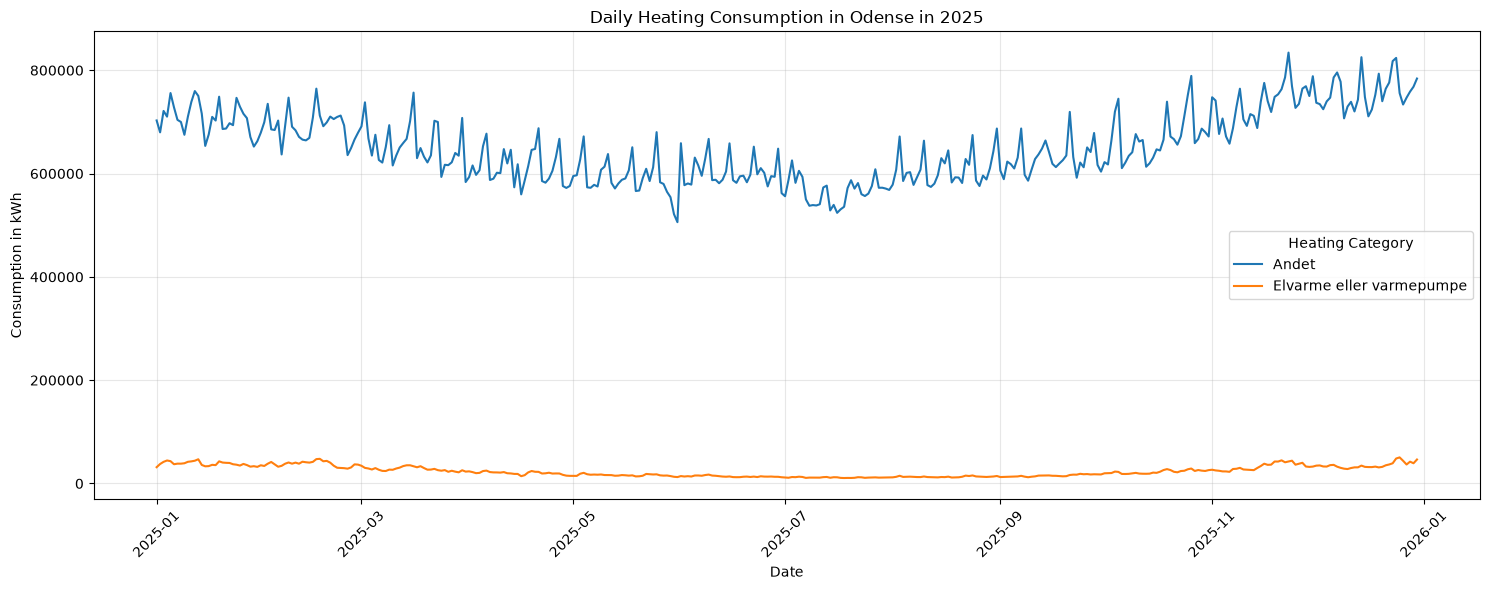

In [16]:
plt.figure(figsize=(15,6))


for category in daily_consumption_df["HeatingCategory"].unique():

    category_df = daily_consumption_df[
        daily_consumption_df["HeatingCategory"] == category
    ]

    plt.plot(
        category_df["Date"],
        category_df["ConsumptionkWh"],
        label=category
    )

    plt.title("Daily Heating Consumption in Odense in 2025")
    plt.xlabel("Date")
    plt.ylabel("Consumption in kWh")
    plt.legend(title = "Heating Category")
    plt.grid(alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show

In [17]:
daily_consumption_df["DailyShare"] = (
    daily_consumption_df
    .groupby("HeatingCategory")["ConsumptionkWh"]
    .transform(lambda x: x / x.sum() * 100)
)

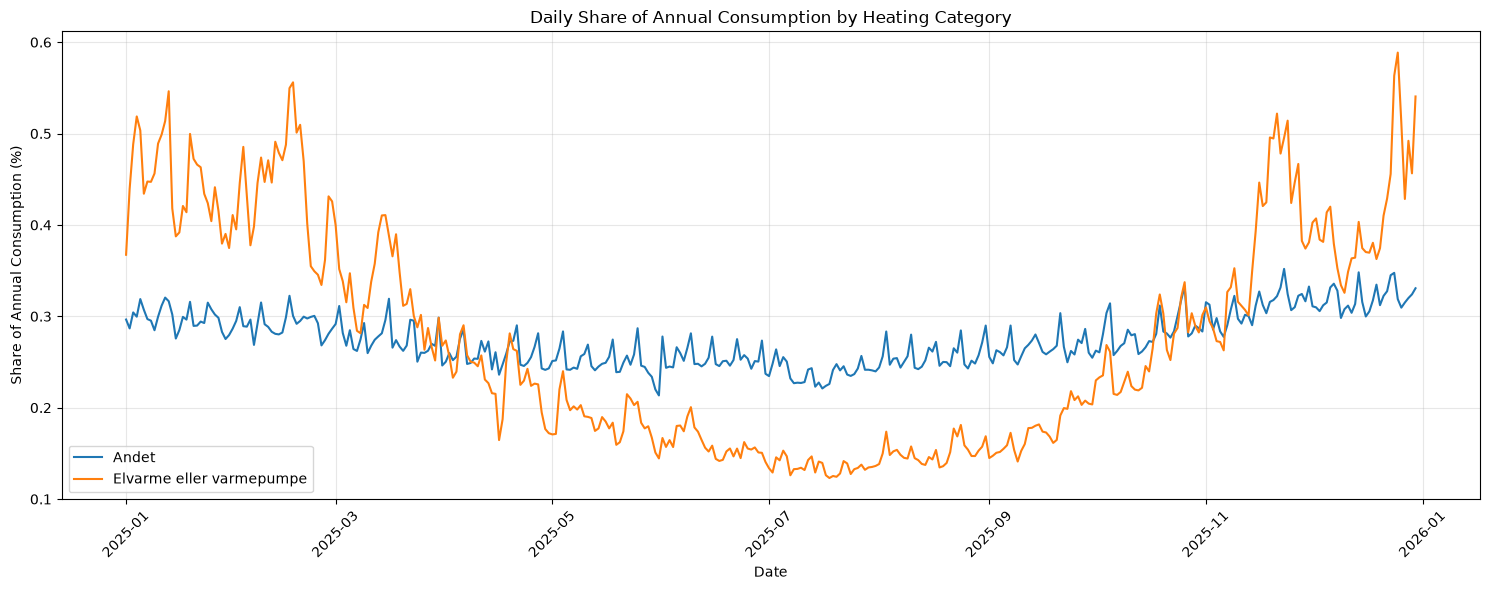

In [18]:
plt.figure(figsize=(15, 6))

for category in daily_consumption_df["HeatingCategory"].unique():

    category_data = daily_consumption_df[
        daily_consumption_df["HeatingCategory"] == category
    ]

    plt.plot(
        category_data["Date"],
        category_data["DailyShare"],
        label=category
    )

plt.title("Daily Share of Annual Consumption by Heating Category")
plt.xlabel("Date")
plt.ylabel("Share of Annual Consumption (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
daily_consumption_df["Month"] = pd.to_datetime(
    daily_consumption_df["Date"]
).dt.month

monthly_consumption_df = (
    daily_consumption_df
    .groupby(["Month", "HeatingCategory"])["ConsumptionkWh"]
    .sum()
    .reset_index()
)

monthly_consumption_df["MonthlyShare"] = (
    monthly_consumption_df
    .groupby("HeatingCategory")["ConsumptionkWh"]
    .transform(lambda x: x / x.sum() * 100)
)

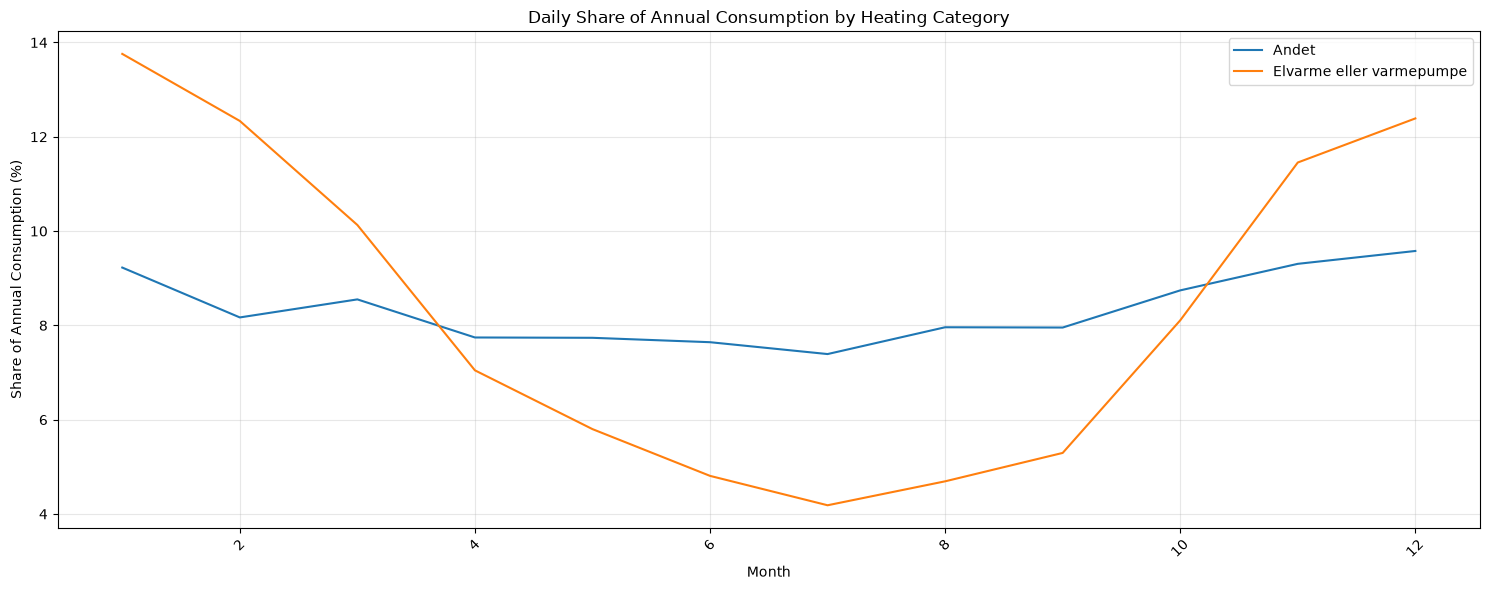

In [20]:
plt.figure(figsize=(15, 6))

for category in monthly_consumption_df["HeatingCategory"].unique():

    category_data = monthly_consumption_df[
        monthly_consumption_df["HeatingCategory"] == category
    ]

    plt.plot(
        category_data["Month"],
        category_data["MonthlyShare"],
        label=category
    )

plt.title("Daily Share of Annual Consumption by Heating Category")
plt.xlabel("Month")
plt.ylabel("Share of Annual Consumption (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
3/5 * (4**4/5**4)

0.24576